# 5. Convergence of Monte Carlo Option Prices

*Part 5 of **Stochastic Modelling and Monte Carlo Methods for Financial Markets**.*

Notebook 3 showed in theory and in a toy example that Monte Carlo error decays like $O(1/\sqrt{N})$. Here the same claim is tested on the option pricer from Notebook 4, using the analytical Black–Scholes price as ground truth.

Questions:

1. How does a single Monte Carlo price approach Black–Scholes as $N = 10^2, 10^3, \dots, 10^7$?
2. Is the empirical convergence rate really $N^{-1/2}$?
3. Do the 95% confidence intervals actually contain the true price 95% of the time?
4. What does a given accuracy cost?

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Make the project's src/ package importable when running from notebooks/
sys.path.insert(0, str(Path.cwd().parent / "src"))

from stochmc import black_scholes_price, price_european_option_mc

SEED = 42
rng = np.random.default_rng(SEED)

FIGURES_DIR = Path.cwd().parent / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

In [2]:
initial_price = 100
strike_price = 100
risk_free_rate = 0.05
annual_volatility = 0.20
time_to_maturity = 1

option_parameters = dict(
    initial_price=initial_price,
    strike_price=strike_price,
    risk_free_rate=risk_free_rate,
    volatility=annual_volatility,
    time_to_maturity=time_to_maturity,
    option_type="call",
)

exact_price = black_scholes_price(
    initial_price, strike_price, risk_free_rate, annual_volatility, time_to_maturity, "call"
)

print(f"Black-Scholes call price: {exact_price:.6f}")

Black-Scholes call price: 10.450584


## 5.1 One run per sample size

One Monte Carlo price is computed for each $N$ from $10^2$ to $10^7$, with its standard error and 95% confidence interval.

In [3]:
single_run_sizes = [10**k for k in range(2, 8)]
single_run_rows = []

for n_samples in single_run_sizes:
    result = price_european_option_mc(**option_parameters, n_samples=n_samples, rng=rng)
    low, high = result.confidence_interval

    single_run_rows.append({
        "N": n_samples,
        "mc_price": result.estimate,
        "standard_error": result.standard_error,
        "ci_95_low": low,
        "ci_95_high": high,
        "abs_error_vs_bs": abs(result.estimate - exact_price),
        "error_in_se_units": (result.estimate - exact_price) / result.standard_error,
        "bs_inside_ci": result.contains(exact_price),
    })

single_runs = pd.DataFrame(single_run_rows).set_index("N")
single_runs

,mc_price,standard_error,ci_95_low,ci_95_high,abs_error_vs_bs,error_in_se_units,bs_inside_ci
N,,,,,,,
100,7.825768,1.011962,5.842359,9.809178,2.624815,-2.593787,False
1000,10.145429,0.458610,9.246571,11.044288,0.305154,-0.665389,True
10000,10.422398,0.148543,10.131259,10.713538,0.028185,-0.189745,True
100000,10.423637,0.046832,10.331847,10.515427,0.026947,-0.575385,True
1000000,10.457500,0.014724,10.428641,10.486360,0.006917,0.469754,True
10000000,10.448828,0.004653,10.439707,10.457948,0.001756,-0.377363,True


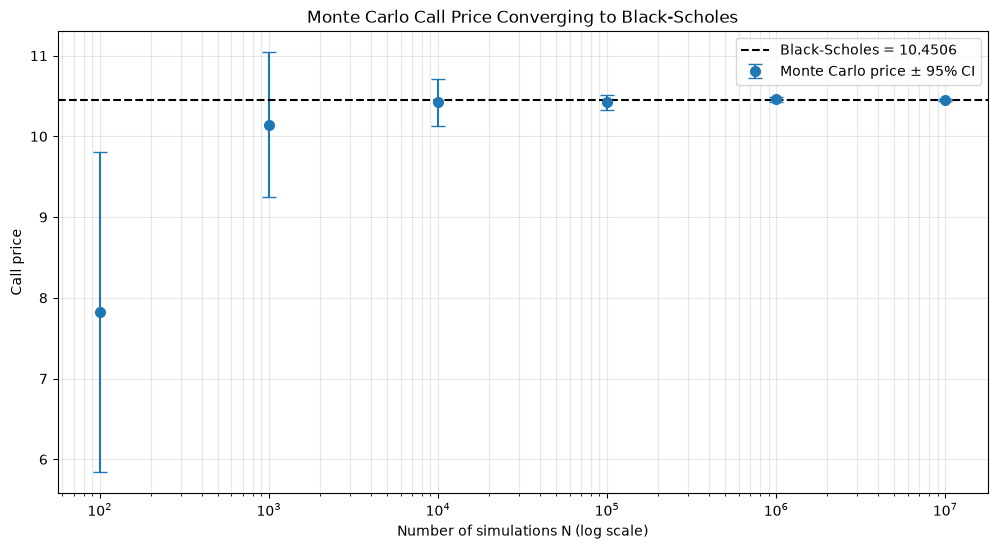

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    single_runs.index,
    single_runs["mc_price"],
    yerr=1.96 * single_runs["standard_error"],
    fmt="o",
    markersize=7,
    capsize=5,
    label="Monte Carlo price ± 95% CI"
)

ax.axhline(exact_price, color="black", linestyle="--", label=f"Black-Scholes = {exact_price:.4f}")

ax.set_xscale("log")
ax.set_title("Monte Carlo Call Price Converging to Black-Scholes")
ax.set_xlabel("Number of simulations N (log scale)")
ax.set_ylabel("Call price")
ax.legend()
ax.grid(alpha=0.3, which="both")

plt.show()

Each tenfold increase in $N$ shrinks the confidence interval by about $\sqrt{10} \approx 3.16$. Going from $10^2$ to $10^7$ samples improves accuracy from about a dollar to well under a cent.

At $N = 100$ the interval misses the true price. A 95% interval is expected to miss about once in twenty runs, and at very small $N$ somewhat more often (see §5.3).

A single run per $N$ is noisy evidence: any one error may be lucky or unlucky. To measure the *rate*, the error has to be averaged over many independent repetitions.

## 5.2 Empirical convergence rate

For each $N$ the pricing experiment is repeated $M$ times, and the following are recorded:

- **bias**: mean of $\hat V_N - V_{BS}$, which should be $\approx 0$;
- **RMSE**: $\sqrt{\text{mean}\big((\hat V_N - V_{BS})^2\big)}$, the typical error;
- **mean reported SE**: the average of each run's own $s/\sqrt{N}$ estimate.

If Monte Carlo behaves as theory says, RMSE ≈ SE ∝ $N^{-1/2}$.

In [5]:
repeated_sizes = np.array([10**2, 10**3, 10**4, 10**5, 10**6])
n_repetitions = 200

repeated_results = {}

for n_samples in repeated_sizes:
    repeated_results[n_samples] = [
        price_european_option_mc(**option_parameters, n_samples=int(n_samples), rng=rng)
        for _ in range(n_repetitions)
    ]

convergence_rows = []

for n_samples, results in repeated_results.items():
    estimates = np.array([r.estimate for r in results])
    errors = estimates - exact_price

    convergence_rows.append({
        "N": n_samples,
        "bias": errors.mean(),
        "bias_standard_error": errors.std(ddof=1) / np.sqrt(n_repetitions),
        "rmse": np.sqrt(np.mean(errors**2)),
        "mean_reported_se": np.mean([r.standard_error for r in results]),
        "ci_coverage": np.mean([r.contains(exact_price) for r in results]),
    })

convergence = pd.DataFrame(convergence_rows).set_index("N")

slope, intercept = np.polyfit(np.log(convergence.index), np.log(convergence["rmse"]), 1)

print(f"Fitted convergence rate: RMSE ∝ N^{slope:.3f}  (theory: N^-0.5)")
convergence

Fitted convergence rate: RMSE ∝ N^-0.503  (theory: N^-0.5)


,bias,bias_standard_error,rmse,mean_reported_se,ci_coverage
N,,,,,
100,0.015971,0.115735,1.632726,1.465383,0.910
1000,-0.060867,0.031895,0.454036,0.463138,0.955
10000,0.003492,0.009894,0.139621,0.147381,0.950
100000,-0.001375,0.003446,0.048628,0.046544,0.935
1000000,0.000508,0.001075,0.015178,0.014721,0.950


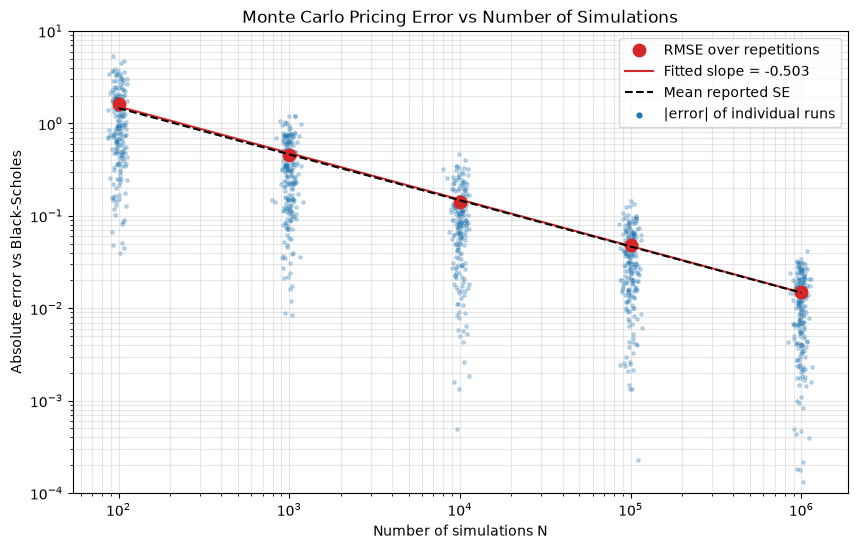

In [6]:
# Separate generator for horizontal jitter so plotting does not consume simulation randomness
jitter_rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(10, 6))

for n_samples, results in repeated_results.items():
    abs_errors = np.abs([r.estimate - exact_price for r in results])
    ax.scatter(
        np.full(n_repetitions, n_samples) * np.exp(jitter_rng.normal(0, 0.06, n_repetitions)),
        abs_errors,
        s=6,
        alpha=0.25,
        color="tab:blue"
    )

ax.loglog(convergence.index, convergence["rmse"], "o", color="tab:red", markersize=9, label="RMSE over repetitions")
ax.loglog(
    convergence.index,
    np.exp(intercept) * convergence.index.to_numpy(dtype=float) ** slope,
    color="tab:red",
    label=f"Fitted slope = {slope:.3f}"
)
ax.loglog(
    convergence.index,
    convergence["mean_reported_se"],
    "k--",
    label="Mean reported SE"
)

ax.scatter([], [], s=12, color="tab:blue", label="|error| of individual runs")

ax.set_ylim(1e-4, 10)
ax.set_title("Monte Carlo Pricing Error vs Number of Simulations")
ax.set_xlabel("Number of simulations N")
ax.set_ylabel("Absolute error vs Black-Scholes")
ax.legend()
ax.grid(alpha=0.3, which="both")

fig.savefig(FIGURES_DIR / "convergence.png", dpi=150, bbox_inches="tight")
plt.show()

The fitted slope is very close to $-\tfrac12$, so the $O(1/\sqrt{N})$ rate holds. The bias is statistically indistinguishable from zero at every $N$, because the estimator is unbiased. The reported standard errors match the actual RMSE, so a single run's own SE is a reliable measure of its accuracy.

## 5.3 Confidence-interval coverage

A nominal 95% interval should contain the true price in 95% of repetitions. Coverage is estimated from the $M$ repetitions above, with a binomial error bar $\sqrt{\hat p(1-\hat p)/M}$.

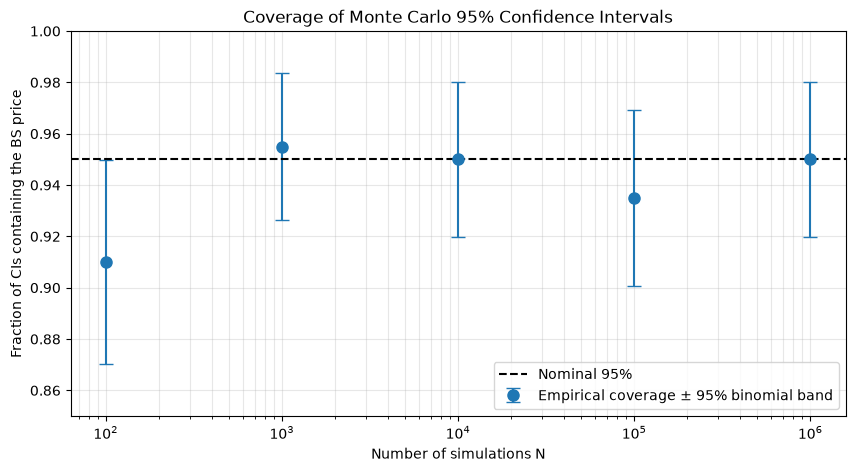

In [7]:
coverage = convergence["ci_coverage"]
coverage_se = np.sqrt(coverage * (1 - coverage) / n_repetitions)

fig, ax = plt.subplots(figsize=(10, 5))

ax.errorbar(
    convergence.index,
    coverage,
    yerr=1.96 * coverage_se,
    fmt="o",
    markersize=8,
    capsize=5,
    label="Empirical coverage ± 95% binomial band"
)
ax.axhline(0.95, color="black", linestyle="--", label="Nominal 95%")

ax.set_xscale("log")
ax.set_ylim(0.85, 1.0)
ax.set_title("Coverage of Monte Carlo 95% Confidence Intervals")
ax.set_xlabel("Number of simulations N")
ax.set_ylabel("Fraction of CIs containing the BS price")
ax.legend(loc="lower right")
ax.grid(alpha=0.3, which="both")

plt.show()

From $N = 10^3$ upward, coverage agrees with 95% within binomial noise. At $N = 100$ it is noticeably lower. The CLT interval assumes $\hat V_N$ is approximately normal, but the call payoff is very skewed (a point mass at zero and a long right tail). With few samples the estimated SE is often too small, because the rare large payoffs that drive the variance are missing from the sample. Once $N$ reaches the thousands the normal approximation is excellent.

## 5.4 The cost of accuracy

Since $\text{SE} = \sigma_f/\sqrt{N}$, the number of samples needed for a target standard error $\varepsilon$ is

$$
N(\varepsilon) = \left(\frac{\sigma_f}{\varepsilon}\right)^2.
$$

Halving the error requires **four times** the work, and each additional decimal digit requires **100 times** the work. The constant $\sigma_f$ (the standard deviation of the discounted payoff) sets the overall cost. This is the quantity that variance reduction attacks.

In [8]:
# sigma_f estimated from the largest single run: SE * sqrt(N)
payoff_std = single_runs.loc[10**7, "standard_error"] * np.sqrt(10**7)

timing_rows = []

for n_samples in [10**4, 10**5, 10**6, 10**7]:
    start = time.perf_counter()
    price_european_option_mc(**option_parameters, n_samples=n_samples, rng=rng)
    elapsed = time.perf_counter() - start

    timing_rows.append({"N": n_samples, "seconds": elapsed})

timing = pd.DataFrame(timing_rows).set_index("N")
seconds_per_sample = (timing["seconds"] / timing.index).iloc[-1]

target_rows = []

for target_se in [0.10, 0.01, 0.001]:
    required_n = (payoff_std / target_se) ** 2
    target_rows.append({
        "target_standard_error": target_se,
        "required_N": f"{required_n:,.0f}",
        "estimated_seconds": required_n * seconds_per_sample,
    })

print(f"Estimated payoff standard deviation sigma_f = {payoff_std:.4f}")
display(timing)
pd.DataFrame(target_rows).set_index("target_standard_error")

Estimated payoff standard deviation sigma_f = 14.7151


,seconds
N,
10000,0.000238
100000,0.001109
1000000,0.011906
10000000,0.118026


,required_N,estimated_seconds
target_standard_error,,
0.100,"21,653",0.000256
0.010,"2,165,350",0.025557
0.001,"216,534,973",2.555684


In [9]:
assert abs(slope + 0.5) < 0.1
assert np.all(np.abs(convergence["bias"]) < 4 * convergence["bias_standard_error"])
assert np.all(convergence["ci_coverage"] > 0.88)
assert np.allclose(convergence["rmse"], convergence["mean_reported_se"], rtol=0.2)

print("Convergence experiment checks passed.")

Convergence experiment checks passed.


## Conclusions

- Monte Carlo option prices converge to the Black–Scholes value, with an error that falls like $N^{-1/2}$ (fitted slope ≈ −0.5).
- The estimator is unbiased, and its self-reported standard error matches the true RMSE.
- 95% confidence intervals have close to nominal coverage, so they can be trusted when no analytical price exists.
- Accuracy is expensive: one more correct digit costs 100× more simulations.

The rate $N^{-1/2}$ cannot be improved by plain random sampling, but the constant $\sigma_f$ can be reduced. Notebook 6 does this with **antithetic variates**.